Choose a starting pension index. A value of 100 means the pension starts at its assumed benchmark value relative to earnings. 100
Enter a simulation horizon in years: 30
Input a probability of an inflation shock occurring in any given year (%): 5
Input the mean effect of an inflation shock. For example, for an average inflation shock of 5%, input 5. Negative values are also allowed. (%): 5
Input the standard deviation of an inflation shock (percentage points): 2
Input a value for how persistent inflation is (between 0 and 1): 0.6
Input a value for the earnings response parameter, which measures how strongly earnings respond to inflation.
A value of 0 means earnings do not respond to inflation, and a value of 1 means a one-for-one response: 0.75
Input a target / long-run average for nominal earnings growth (%): 3
Input a value for the standard deviation of the random inflation disturbance that occurs each year (percentage points): 1.5
Input a value for the standard deviation of the rand

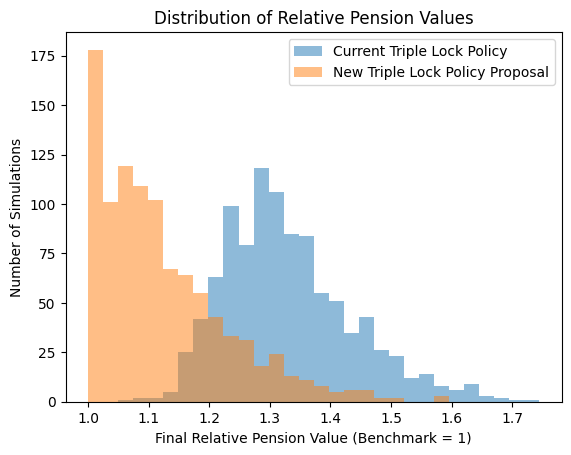

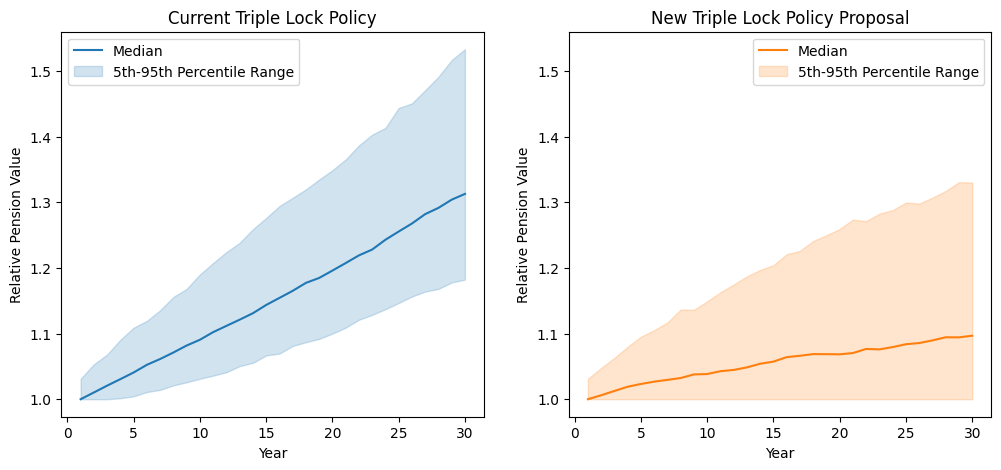

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math

rng = np.random.default_rng()

def get_float(prompt):
  while True:
    try:
      number = float(input(prompt))
      if math.isfinite(number):
        return number
      else:
        print("Invalid input. Please enter a finite number.")
    except ValueError:
      print("Invalid input. Please enter a number.")

def get_int(prompt):
  while True:
    try:
      return int(input(prompt))
    except ValueError:
      print("Invalid input. Please enter a whole number.")


starting_pension_index = get_float("Choose a starting pension index. A value of 100 means the pension starts at its assumed benchmark value relative to earnings. ")
while starting_pension_index < 100:
  starting_pension_index = get_float("Choose a new starting pension index. The number must be 100 or above: ")

pension_rise_floor = 0.025

simulation_horizon_in_years = get_int("Enter a simulation horizon in years: ")
while simulation_horizon_in_years < 1:
  simulation_horizon_in_years = get_int(" The simulation horizon must be at least one year. Enter a new value: ")

inflation_shock_probability = get_float("Input a probability of an inflation shock occurring in any given year (%): ") / 100
while inflation_shock_probability < 0 or inflation_shock_probability > 1:
  inflation_shock_probability = get_float("Input a probability of an inflation shock occurring in any given year (between 0% and 100%): ") / 100
inflation_shock_mean = get_float("Input the mean effect of an inflation shock. For example, for an average inflation shock of 5%, input 5. Negative values are also allowed. (%): ") / 100
inflation_shock_sd = get_float("Input the standard deviation of an inflation shock (percentage points): ") / 100
while inflation_shock_sd < 0:
  inflation_shock_sd = get_float("Your number must be greater than or equal to zero. Input the standard deviation of an inflation shock:") / 100
inflation_persistence = get_float("Input a value for how persistent inflation is (between 0 and 1): ")
while inflation_persistence < 0 or inflation_persistence >= 1:
  inflation_persistence = get_float("Your value must be between 0 and 1. Input a value for how persistent inflation is: ")

earnings_response_parameter = get_float("Input a value for the earnings response parameter, which measures how strongly earnings respond to inflation.\nA value of 0 means earnings do not respond to inflation, and a value of 1 means a one-for-one response: ")
while earnings_response_parameter < 0 or earnings_response_parameter > 1:
  earnings_response_parameter = get_float("Your value must be between 0 and 1. Input a new value for the earnings response parameter: ")

inflation_target = 0.02
earnings_target = get_float("Input a target / long-run average for nominal earnings growth (%): ") / 100
while earnings_target <= -1:
  earnings_target = get_float("The long-run earnings growth rate must be greater than -100%. Enter a new value: ") / 100
expected_shock = inflation_shock_probability * inflation_shock_mean
inflation_disturbance_sd = get_float("Input a value for the standard deviation of the random inflation disturbance that occurs each year (percentage points): ") / 100
while inflation_disturbance_sd < 0:
  inflation_disturbance_sd = get_float("The value must be greater than or equal to zero. Input a new value for the standard deviation of the random inflation disturbance: ") / 100
earnings_disturbance_sd = get_float("Input a value for the standard deviation of the random earnings disturbance that occurs each year (percentage points): ") / 100
while earnings_disturbance_sd < 0:
  earnings_disturbance_sd = get_float("The value must be greater than or equal to zero. Input a new value for the standard deviation of the random earnings disturbance: ") / 100

old_pension_final_ratios = []
new_pension_final_ratios = []

number_of_simulations = get_int("Input the number of simulations that will be performed: ")
while number_of_simulations <= 0:
  number_of_simulations = get_int("This number must be above 0. Please enter a new number of simulations: ")

all_old_pension_ratios = []
all_new_pension_ratios = []


for simulation in range(number_of_simulations):
  old_pension_index = new_pension_index = starting_pension_index
  average_earnings_index = 100
  previous_inflation = inflation_target
  old_pension_annual_ratios = []
  new_pension_annual_ratios = []
  for year in range(1, simulation_horizon_in_years + 1):
    inflation_disturbance = rng.normal(0, inflation_disturbance_sd)
    earnings_disturbance = rng.normal(0, earnings_disturbance_sd)
    inflation = inflation_target + (inflation_persistence * (previous_inflation - inflation_target)) + inflation_disturbance - expected_shock
    if rng.random() < inflation_shock_probability:
      inflation_shock = rng.normal(inflation_shock_mean, inflation_shock_sd)
      inflation += inflation_shock
    if inflation <= -1:
      raise ValueError("Invalid economic scenario")
    average_earnings_growth = earnings_target + (earnings_response_parameter * (previous_inflation - inflation_target)) + earnings_disturbance
    if average_earnings_growth <= -1:
      raise ValueError("Invalid economic scenario")
    average_earnings_index = average_earnings_index * (1 + average_earnings_growth)
    previous_inflation = inflation
    old_pension_index = old_pension_index * (1 + max(inflation, average_earnings_growth, pension_rise_floor))
    new_pension_index = max((new_pension_index * (1 + max(inflation, pension_rise_floor))), average_earnings_index)
    old_pension_relative_value = old_pension_index / average_earnings_index
    new_pension_relative_value = new_pension_index / average_earnings_index
    old_pension_annual_ratios.append(old_pension_relative_value)
    new_pension_annual_ratios.append(new_pension_relative_value)
  old_pension_final_ratios.append(old_pension_annual_ratios[-1])
  new_pension_final_ratios.append(new_pension_annual_ratios[-1])
  all_old_pension_ratios.append(old_pension_annual_ratios)
  all_new_pension_ratios.append(new_pension_annual_ratios)



old_pension_mean_ratio = np.mean(old_pension_final_ratios)
new_pension_mean_ratio = np.mean(new_pension_final_ratios)
old_pension_median_ratio = np.median(old_pension_final_ratios)
new_pension_median_ratio = np.median(new_pension_final_ratios)
old_pension_5th_percentile = np.percentile(old_pension_final_ratios, 5)
new_pension_5th_percentile = np.percentile(new_pension_final_ratios, 5)
old_pension_95th_percentile = np.percentile(old_pension_final_ratios, 95)
new_pension_95th_percentile = np.percentile(new_pension_final_ratios, 95)

print("Mean final relative pension value (Current Triple Lock):", round(old_pension_mean_ratio, 2))
print("Mean final relative pension value (New Triple Lock):", round(new_pension_mean_ratio, 2))
print("Median final relative pension value (Current Triple Lock):", round(old_pension_median_ratio, 2))
print("Median final relative pension value (New Triple Lock):", round(new_pension_median_ratio, 2))
print("5th percentile of final relative pension value (Current Triple Lock):", round(old_pension_5th_percentile, 2))
print("5th percentile of final relative pension value (New Triple Lock):", round(new_pension_5th_percentile, 2))
print("95th percentile of final relative pension value (Current Triple Lock):", round(old_pension_95th_percentile, 2))
print("95th percentile of final relative pension value (New Triple Lock):", round(new_pension_95th_percentile, 2))

all_final_ratios = old_pension_final_ratios + new_pension_final_ratios
common_bins = np.histogram_bin_edges(all_final_ratios, 30)

plt.hist(old_pension_final_ratios, bins=common_bins, alpha=0.5, label='Current Triple Lock Policy')
plt.hist(new_pension_final_ratios, bins=common_bins,alpha=0.5, label='New Triple Lock Policy Proposal')
plt.xlabel('Final Relative Pension Value (Benchmark = 1)')
plt.ylabel('Number of Simulations')
plt.title('Distribution of Relative Pension Values')
plt.legend()
plt.show()


old_pension_annual_medians = []
old_pension_annual_5th_percentiles = []
old_pension_annual_95th_percentiles = []
new_pension_annual_medians = []
new_pension_annual_5th_percentiles = []
new_pension_annual_95th_percentiles = []


for year in range(simulation_horizon_in_years):
  old_year_ratios = []
  new_year_ratios = []
  for simulation in range(number_of_simulations):
    old_year_ratios.append(all_old_pension_ratios[simulation][year])
    new_year_ratios.append(all_new_pension_ratios[simulation][year])
  old_pension_annual_medians.append(np.median(old_year_ratios))
  old_pension_annual_5th_percentiles.append(np.percentile(old_year_ratios, 5))
  old_pension_annual_95th_percentiles.append(np.percentile(old_year_ratios, 95))
  new_pension_annual_medians.append(np.median(new_year_ratios))
  new_pension_annual_5th_percentiles.append(np.percentile(new_year_ratios, 5))
  new_pension_annual_95th_percentiles.append(np.percentile(new_year_ratios, 95))

plt.figure(figsize=(12,5))

ax1 = plt.subplot(1,2,1)
plt.plot(range(1, simulation_horizon_in_years + 1), old_pension_annual_medians, color='#1f77b4', label='Median')
plt.fill_between(range(1, simulation_horizon_in_years + 1), old_pension_annual_5th_percentiles, old_pension_annual_95th_percentiles, alpha=0.2, color='#1f77b4', label='5th-95th Percentile Range')
plt.title('Current Triple Lock Policy')
plt.xlabel('Year')
plt.ylabel('Relative Pension Value')
plt.legend()


ax2 = plt.subplot(1,2,2, sharex=ax1, sharey=ax1)
plt.plot(range(1, simulation_horizon_in_years + 1), new_pension_annual_medians, color='#ff7f0e', label="Median")
plt.fill_between(range(1, simulation_horizon_in_years +1), new_pension_annual_5th_percentiles, new_pension_annual_95th_percentiles, alpha=0.2, color='#ff7f0e', label='5th-95th Percentile Range')
plt.title("New Triple Lock Policy Proposal")
plt.xlabel('Year')
plt.ylabel('Relative Pension Value')
plt.legend()

plt.show()

